In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

In [3]:
ticker = yf.Ticker("AAPL")
data = ticker.history(
    period = "5y",
    interval = "1d",
    auto_adjust = True,
)
data.tail()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-11-02 00:00:00-05:00,342.670013,343.799988,335.820007,338.320007,64757700,0.0,0.0
2026-11-03 00:00:00-05:00,325.579987,334.500000,325.329987,331.899994,63160000,0.0,0.0
2026-11-04 00:00:00-05:00,341.570007,354.500000,340.989990,349.510010,89637700,0.0,0.0
2026-11-05 00:00:00-05:00,353.890015,355.380005,342.059998,344.170013,75457100,0.0,0.0
2026-11-06 00:00:00-05:00,338.299988,345.790009,338.299988,344.529999,15249265,0.0,0.0


In [5]:
print('Tamaño del dataframe: ', data.shape)

print('\nInformación', data.info())

print('\nEstadísticos del preciode cierre:')
print(data['Close'].describe())

Tamaño del dataframe:  (1255, 7)
<class 'pandas.DataFrame'>
DatetimeIndex: 1255 entries, 2021-11-08 00:00:00-05:00 to 2026-11-06 00:00:00-05:00
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Open          1255 non-null   float64
 1   High          1255 non-null   float64
 2   Low           1255 non-null   float64
 3   Close         1255 non-null   float64
 4   Volume        1255 non-null   int64  
 5   Dividends     1255 non-null   float64
 6   Stock Splits  1255 non-null   float64
dtypes: float64(6), int64(1)
memory usage: 78.4 KB

Información None

Estadísticos del preciode cierre:
count    1255.000000
mean      206.833157
std        54.297386
min       122.827614
25%       165.824081
50%       191.248398
75%       241.174782
max       349.510010
Name: Close, dtype: float64


### Feature Engineering: rentabilidades e indicadores ###

**Rentabilidad diaria:** Variación porcentual frente a la observación anterior, matemáticacmente:
$$R_t = \frac{P_t-P_{t-1}}{P_{t-1}}$$

In [15]:
#Creamos una columna en nuestro data frame
data['Daily_Return'] = data['Close'].pct_change()
data['Daily_Return'].head()

Date
2021-11-08 00:00:00-05:00         NaN
2021-11-09 00:00:00-05:00    0.002459
2021-11-10 00:00:00-05:00   -0.019163
2021-11-11 00:00:00-05:00   -0.000338
2021-11-12 00:00:00-05:00    0.014337
Name: Daily_Return, dtype: float64

**Rentabilidad acumulada:** Queremos saber como evoluciona una inverión inicial de una unidad monetaria si la huieramos mantenido durante todo el periodo

In [16]:
#Cumprod hace el producto acumulado
data['Cumulative_Return'] = (1 + data["Daily_Return"]).cumprod() - 1
data['Cumulative_Return'].head()

Date
2021-11-08 00:00:00-05:00         NaN
2021-11-09 00:00:00-05:00    0.002459
2021-11-10 00:00:00-05:00   -0.016751
2021-11-11 00:00:00-05:00   -0.017083
2021-11-12 00:00:00-05:00   -0.002991
Name: Cumulative_Return, dtype: float64

**Medias Móviles**: Incorporamos las medias de los últimos 20 y 50 días.
$${SMA}_{20} = \frac{P_t+P_{t-1}+\dots+P_{t-19}}{20}$$
$${SMA}_{50} = \frac{P_t+P_{t-1}+\dots+P_{t-49}}{50}$$

In [19]:
data['SMA_20'] = data['Close'].rolling(window = 20).mean()
data['SMA_50'] = data['Close'].rolling(window = 50).mean()
data[['SMA_20','SMA_50']].tail()

,SMA_20,SMA_50
Date,,
2026-11-02 00:00:00-05:00,342.355002,333.620201
2026-11-03 00:00:00-05:00,342.268501,334.051401
2026-11-04 00:00:00-05:00,342.910501,334.843601
2026-11-05 00:00:00-05:00,343.098001,335.458001
2026-11-06 00:00:00-05:00,343.492500,336.057001


**Momentum:** Mide cuanto ha variado el precio frente al de hace $n$ sesiones. (igual que la rentabilidad diaria pero a 20 días)
$$M_{n} = \frac{P_t}{P_{t-n}}-1$$

In [20]:
data['Close'].pct_change(20)

Date
2021-11-08 00:00:00-05:00         NaN
2021-11-09 00:00:00-05:00         NaN
2021-11-10 00:00:00-05:00         NaN
2021-11-11 00:00:00-05:00         NaN
2021-11-12 00:00:00-05:00         NaN
                               ...   
2026-11-02 00:00:00-05:00    0.016312
2026-11-03 00:00:00-05:00   -0.005185
2026-11-04 00:00:00-05:00    0.038138
2026-11-05 00:00:00-05:00    0.011016
2026-11-06 00:00:00-05:00    0.023437
Name: Close, Length: 1255, dtype: float64

**Volatilidad anualizada:** Calcularemos la desviación tipica de los retornos de 20 días y la anualizaremos multiplicando por $\sqrt(252)$, que es aproximadamente el número de días que abre el mercado financiero en un año. Es decir,
$$\sigma_{anual} = \sigma_{diaria}\cdot \sqrt{252}$$

In [22]:
data["Volatility_20"] = (
    data["Daily_Return"]
    .rolling(window=20)
    .std()
    * np.sqrt(252)
)
data['Volatility_20'].tail()

Date
2026-11-02 00:00:00-05:00    0.161556
2026-11-03 00:00:00-05:00    0.176056
2026-11-04 00:00:00-05:00    0.257267
2026-11-05 00:00:00-05:00    0.261864
2026-11-06 00:00:00-05:00    0.258141
Name: Volatility_20, dtype: float64

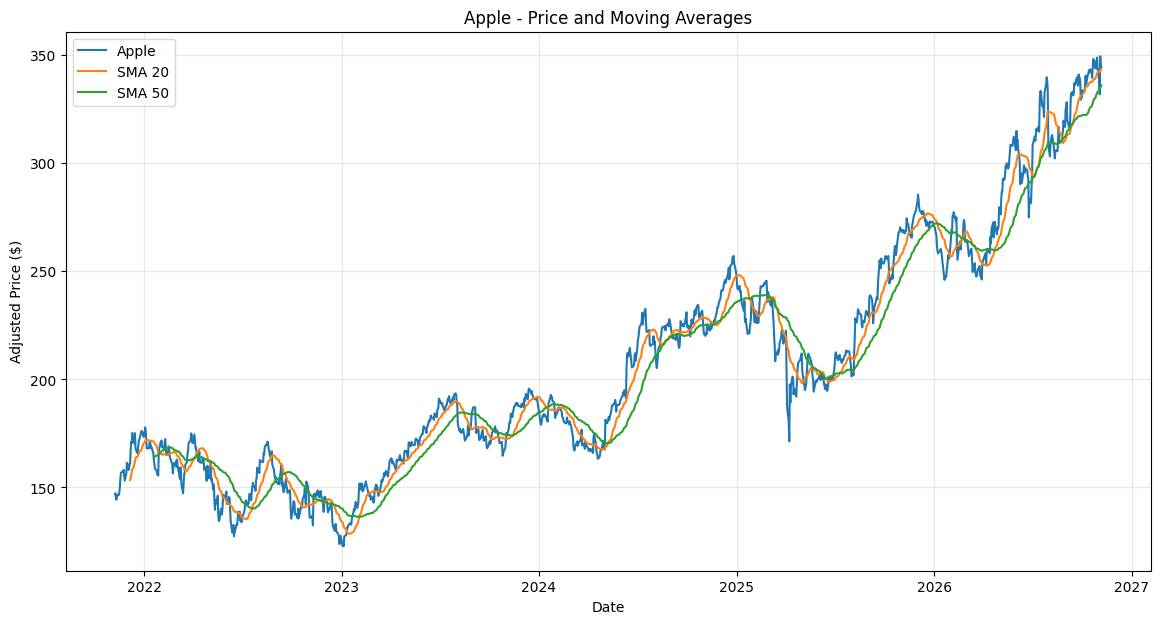

In [23]:
#Sacamos por pantalla lo que hemos obtenido hasta ahora

plt.figure(figsize=(14, 7))

plt.plot(data.index, data["Close"], label="Apple")
plt.plot(data.index, data["SMA_20"], label="SMA 20")
plt.plot(data.index, data["SMA_50"], label="SMA 50")

plt.title("Apple - Price and Moving Averages")
plt.xlabel("Date")
plt.ylabel("Adjusted Price ($)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()